In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier,plot_tree
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report

In [4]:
df=pd.read_csv("Lifestyle_and_Health_Risk_Prediction_Synthetic_Dataset.csv")
df.head()

,age,weight,height,exercise,sleep,sugar_intake,smoking,alcohol,married,profession,bmi,health_risk
0,56,67,195,low,6.1,medium,yes,yes,yes,office_worker,17.6,high
1,69,76,170,high,6.9,high,no,no,no,teacher,26.3,high
2,46,106,153,high,6.6,low,yes,no,no,artist,45.3,high
3,32,54,186,medium,8.5,medium,no,no,no,artist,15.6,low
4,60,98,195,high,8.0,low,no,no,yes,teacher,25.8,high


In [5]:
df.shape

(5000, 12)

In [6]:
df.info

<bound method DataFrame.info of       age  weight  height exercise  sleep sugar_intake smoking alcohol  \
0      56      67     195      low    6.1       medium     yes     yes   
1      69      76     170     high    6.9         high      no      no   
2      46     106     153     high    6.6          low     yes      no   
3      32      54     186   medium    8.5       medium      no      no   
4      60      98     195     high    8.0          low      no      no   
...   ...     ...     ...      ...    ...          ...     ...     ...   
4995   42      75     187   medium    7.2          low      no      no   
4996   39      86     183      low    7.4          low      no      no   
4997   48      56     194     none    7.2         high     yes     yes   
4998   34     109     148   medium    9.9       medium      no      no   
4999   72      47     149     high    6.3       medium      no      no   

     married     profession   bmi health_risk  
0        yes  office_worker  17

In [7]:
df.isna().sum()

age             0
weight          0
height          0
exercise        0
sleep           0
sugar_intake    0
smoking         0
alcohol         0
married         0
profession      0
bmi             0
health_risk     0
dtype: int64

In [27]:
df.columns

Index(['age', 'weight', 'height', 'exercise', 'sleep', 'sugar_intake',
       'smoking', 'alcohol', 'married', 'profession', 'bmi', 'health_risk'],
      dtype='str')

In [8]:
df.describe()

,age,weight,height,sleep,bmi
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.00000
mean,48.805600,77.359200,171.933200,6.997060,26.84388
std,17.906991,18.714567,15.822225,1.432849,8.25249
min,18.000000,45.000000,145.000000,3.000000,11.40000
25%,34.000000,61.000000,158.000000,6.000000,20.30000
50%,49.000000,77.000000,171.500000,7.000000,26.00000
75%,64.000000,94.000000,186.000000,8.000000,32.40000
max,79.000000,109.000000,199.000000,10.000000,51.40000


In [9]:
df["health_risk"].value_counts()

health_risk
high    3490
low     1510
Name: count, dtype: int64

In [13]:
x=df.drop("health_risk",axis=1)
y=df["health_risk"]
x.head()

,age,weight,height,exercise,sleep,sugar_intake,smoking,alcohol,married,profession,bmi
0,56,67,195,low,6.1,medium,yes,yes,yes,office_worker,17.6
1,69,76,170,high,6.9,high,no,no,no,teacher,26.3
2,46,106,153,high,6.6,low,yes,no,no,artist,45.3
3,32,54,186,medium,8.5,medium,no,no,no,artist,15.6
4,60,98,195,high,8.0,low,no,no,yes,teacher,25.8


In [14]:
x=pd.get_dummies(x)
x.head()

,age,weight,height,sleep,bmi,exercise_high,exercise_low,exercise_medium,exercise_none,sugar_intake_high,...,married_no,married_yes,profession_artist,profession_doctor,profession_driver,profession_engineer,profession_farmer,profession_office_worker,profession_student,profession_teacher
0,56,67,195,6.1,17.6,False,True,False,False,False,...,False,True,False,False,False,False,False,True,False,False
1,69,76,170,6.9,26.3,True,False,False,False,True,...,True,False,False,False,False,False,False,False,False,True
2,46,106,153,6.6,45.3,True,False,False,False,False,...,True,False,True,False,False,False,False,False,False,False
3,32,54,186,8.5,15.6,False,False,True,False,False,...,True,False,True,False,False,False,False,False,False,False
4,60,98,195,8.0,25.8,True,False,False,False,False,...,False,True,False,False,False,False,False,False,False,True


In [15]:
x_train,x_test,y_train,y_test=train_test_split(
    x,
    y,
    test_size=0.25,
    random_state=32,
    stratify=y
)

In [16]:
model=DecisionTreeClassifier(
    max_depth=3,
    random_state=32
)
model.fit(x_train,y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",3
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",32
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in

In [18]:
y_pred=model.predict(x_test)
y_pred[:10]

array(['low', 'high', 'low', 'low', 'high', 'low', 'high', 'high', 'high',
       'high'], dtype=object)

In [19]:
print("accuracy:",accuracy_score(y_test,y_pred))

accuracy: 0.8512


In [20]:
confusion_matrix(y_test,y_pred)

array([[854,  18],
       [168, 210]])

In [21]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

        high       0.84      0.98      0.90       872
         low       0.92      0.56      0.69       378

    accuracy                           0.85      1250
   macro avg       0.88      0.77      0.80      1250
weighted avg       0.86      0.85      0.84      1250



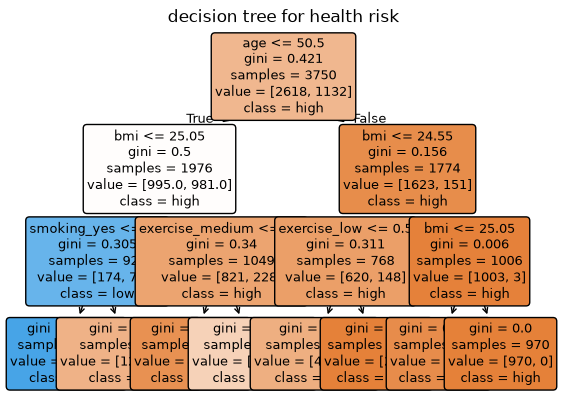

In [23]:
plt.Figure(figsize=(8,5))
plot_tree(
    model,
    feature_names=x.columns,
    class_names=model.classes_,
    filled=True,
    rounded=True,
    fontsize=9
)
plt.title("decision tree for health risk")
plt.show()

In [25]:
feature_importance=pd.DataFrame({
    "feature":x.columns,
    "importance":model.feature_importances_
})
feature_importance=feature_importance.sort_values(
    by="importance",
    ascending=False
)
feature_importance.head()

,feature,importance
4,bmi,0.433231
0,age,0.360434
13,smoking_yes,0.137477
7,exercise_medium,0.044237
6,exercise_low,0.024621


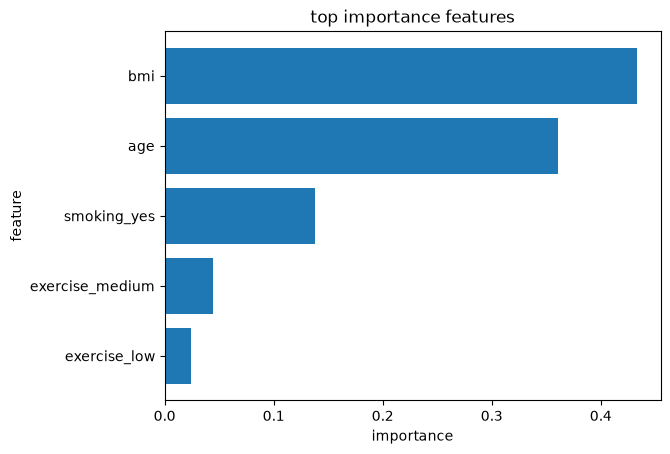

In [26]:
top_features=feature_importance.head()

plt.Figure(figsize=(8,5))
plt.barh(top_features["feature"],top_features["importance"])
plt.xlabel("importance")
plt.ylabel("feature")
plt.title("top importance features")
plt.gca().invert_yaxis()
plt.show()

In [28]:
new_person=pd.DataFrame({
    'age':[15],
    'weight':[85],
    'height':[176],
    'exercise':["low"],
    'sleep':[8],
    'sugar_intake':["low"],
    'smoking':["no"],
    'alcohol':["no"], 
    'married':["no"],
    'profession':["studend"],
    'bmi':[20]
     
})
new_person_encoded=pd.get_dummies(new_person)

new_person_encoded=new_person_encoded.reindex(
    columns=x.columns,
    fill_value=0
)
prediction=model.predict(new_person_encoded)
print("predicted health risk:",prediction[0])                                

predicted health risk: low


In [29]:
model_deeper=DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)
model_deeper.fit(x_train,y_train)
y_pred_deeper=model_deeper.predict(x_test)
print("accuracy with max_depth=5:",accuracy_score(y_test,y_pred_deeper))
print(classification_report(y_test,y_pred_deeper))


accuracy with max_depth=5: 0.8752
              precision    recall  f1-score   support

        high       0.88      0.95      0.91       872
         low       0.85      0.71      0.78       378

    accuracy                           0.88      1250
   macro avg       0.87      0.83      0.84      1250
weighted avg       0.87      0.88      0.87      1250

